<a href="https://colab.research.google.com/github/Abdoulaye279/Quantum-Computing/blob/main/03_correlated_noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Fast noise vs slow drift

In 02 the laser phase was random and independent on every pulse. Here the laser frequency follows an Ornstein-Uhlenbeck process with correlation time tau, and each pulse gets the accumulated phase at its midpoint. The total phase spread over the gate (Phi) is kept fixed, only tau changes.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Quantum-Computing
    %cd Quantum-Computing
except ImportError:
    pass

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cirac_zoller import *
plt.style.use("quant.mplstyle")

labels = ["SS", "SD", "DS", "DD"]

gate duration (us): 517


Phi=0.5: [0.882 0.892 0.897 0.929 0.941]


Phi=1.0: [0.659 0.677 0.705 0.775 0.799]


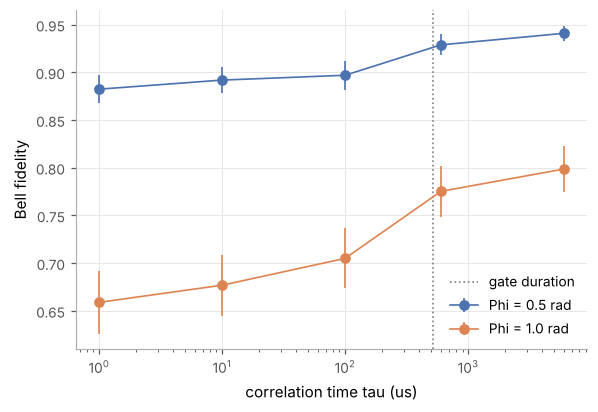

In [3]:
print("gate duration (us):", round(GATE_T))
taus = [1, 10, 100, 600, 6000]
fig, ax = plt.subplots(figsize=(6, 4))
for Phi in [0.5, 1.0]:
    m, e = [], []
    for tau in taus:
        sd = sigma_for_phase(Phi, tau)
        F = [bell_fidelity(bell_rho(gate_corr(np.random.default_rng(s), sd, tau))) for s in range(80)]
        m.append(np.mean(F)); e.append(np.std(F) / np.sqrt(len(F)))
    ax.errorbar(taus, m, yerr=e, marker="o", label=f"Phi = {Phi} rad")
    print(f"Phi={Phi}:", np.round(m, 3))
ax.axvline(GATE_T, color="gray", ls=":", label="gate duration")
ax.set_xscale("log"); ax.set_xlabel("correlation time tau (us)"); ax.set_ylabel("Bell fidelity")
ax.legend(); plt.show()
# same accumulated phase, but a slow drift (tau >~ gate duration) hurts less than fast noise:
# Phi=1: 0.66 for tau=1us vs 0.80 for tau=6000us
# my guess: the Ramsey structure of the sequence partly cancels a phase that stays the same during the gate
# limit: only the pulse phase is noisy, no detuning during the pulses